Epoch 1/15


C:\Users\EiLi1\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5685 - loss: 1.2779 - val_accuracy: 0.7867 - val_loss: 0.6830
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8278 - loss: 0.5479 - val_accuracy: 0.8567 - val_loss: 0.5063
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8963 - loss: 0.3434 - val_accuracy: 0.8567 - val_loss: 0.4622
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9285 - loss: 0.2338 - val_accuracy: 0.8700 - val_loss: 0.3693
Epoch 5/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9452 - loss: 0.1635 - val_accuracy: 0.9000 - val_loss: 0.2986
Epoch 6/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9626 - loss: 0.1160 - val_accuracy: 0.8867 - val_loss: 0.3368
Epoch 7/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9659 - loss: 0.1004 - val_accuracy: 0.9267 - val_loss: 0.2350
Epoch 8/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9796 - loss: 0.0626 - val_accuracy: 0.9233 - val_loss: 0.2601
Ep

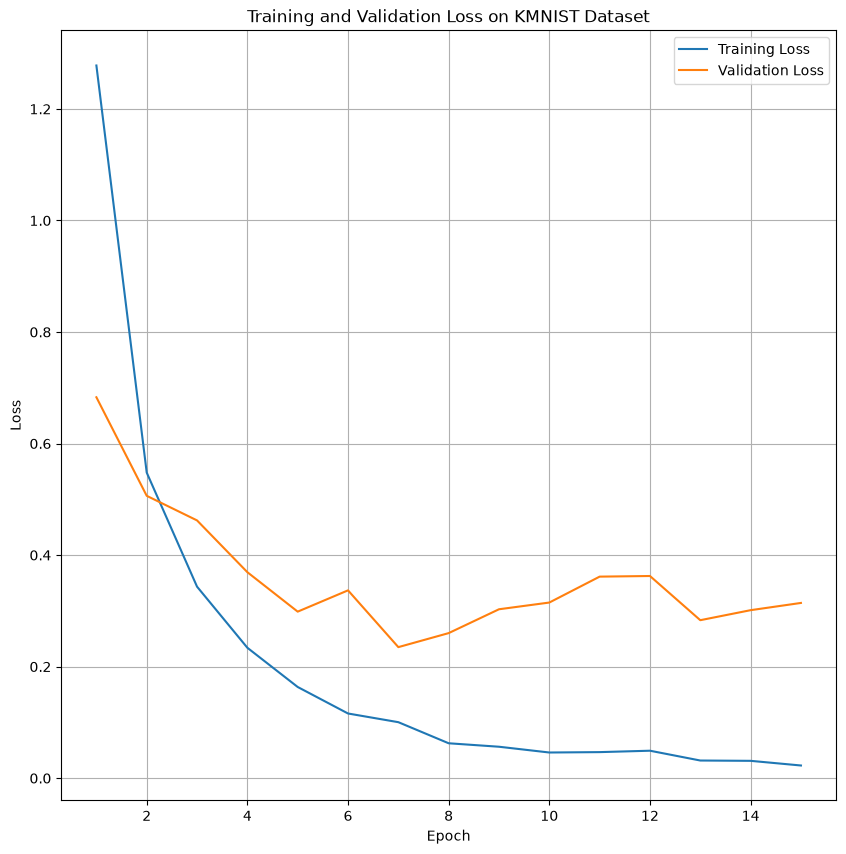

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

# set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# load training and test data from the KMNIST dataset
train_ds, test_ds = tfds.load(
    "kmnist",
    split=["train[:3000]", "test[:500]"],
    as_supervised=True,
    shuffle_files=False
)

# reserve the last 300 images for validation, and the first 2700 for training
validation_ds = train_ds.skip(2700)
train_ds = train_ds.take(2700)

# normalize pixel values from [0, 255] to [0, 1]
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = train_ds.map(normalize)
validation_ds = validation_ds.map(normalize)
test_ds = test_ds.map(normalize)

# batch datasets
train_ds = train_ds.batch(32)
validation_ds = validation_ds.batch(32)
test_ds = test_ds.batch(32)

# build deeper CNN model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # first convolutional block with 32 filters
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # second convolutional block with 64 filters
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # flatten features maps into 1D
    tf.keras.layers.Flatten(),

    # fully connected layer with dropout for regularization
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    # output layer with one neuron for each category
    tf.keras.layers.Dense(10, activation="softmax")
])

# configure Adam optimizer with a learning rate of 0.001
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# compile model with Adam optimizer, loss function and accuracy metric
model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# train model using 10% of training data for validation
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=15,
)

# evaluate model on test data and report accuracy in percentage
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(10, 10))

epochs = range(1, len(history.history["loss"]) + 1)

plt.plot(epochs, history.history["loss"], label="Training Loss")
plt.plot(epochs, history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss on KMNIST Dataset")
plt.legend()
plt.grid(True)
plt.show()